In [15]:
import os
import subprocess

SPARK_HOME = "/content/spark-3.5.0-bin-hadoop3"

env = os.environ.copy()
env["SPARK_HOME"] = SPARK_HOME
env["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"

print("Stopping Spark Worker...")

subprocess.run(
    [f"{SPARK_HOME}/sbin/stop-worker.sh"],
    env=env
)

print("\nStopping Spark Master...")

subprocess.run(
    [f"{SPARK_HOME}/sbin/stop-master.sh"],
    env=env
)

print("\nSpark 3.5.0 cluster shutdown completed.")

Stopping Spark Worker...

Stopping Spark Master...

Spark 3.5.0 cluster shutdown completed.


### Spark standalone setup



In [16]:

import os
import pathlib
import subprocess
import urllib.request
import tarfile
import time

spark_home = pathlib.Path('/content/spark-3.5.0-bin-hadoop3')
java_home = pathlib.Path('/usr/lib/jvm/java-17-openjdk-amd64')

if not java_home.exists():
    subprocess.run(['apt-get', 'update', '-qq'], check=True)
    subprocess.run(['apt-get', 'install', '-y', '-qq', 'openjdk-17-jdk-headless'], check=True)

os.environ['JAVA_HOME'] = str(java_home)
os.environ['SPARK_HOME'] = str(spark_home)
os.environ['PATH'] = f"{java_home / 'bin'}:{spark_home / 'bin'}:" + os.environ['PATH']

if not (spark_home / 'bin' / 'spark-submit').is_file():
    archive = pathlib.Path('/content/spark-3.5.0-bin-hadoop3.tgz')
    url = 'https://archive.apache.org/dist/spark/spark-3.5.0/spark-3.5.0-bin-hadoop3.tgz'
    urllib.request.urlretrieve(url, archive)
    with tarfile.open(archive, 'r:gz') as tar:
        tar.extractall('/content', filter='data')

print('Spark executable:', spark_home / 'bin' / 'spark-submit')
print('Spark executable exists:', (spark_home / 'bin' / 'spark-submit').is_file())
print(subprocess.run(['java', '-version'], capture_output=True, text=True).stderr)

# Stop leftover services if this setup cell is rerun.
for script in ('stop-worker.sh', 'stop-master.sh'):
    subprocess.run([str(spark_home / 'sbin' / script)], env=os.environ.copy(), capture_output=True)

subprocess.run([str(spark_home / 'sbin' / 'start-master.sh'), '--host', 'localhost', '--port', '7077'], env=os.environ.copy(), check=True)
time.sleep(4)
for worker_num in range(4):
    # Start four separate workers, each offering one core.
    worker_env = os.environ.copy()
    worker_env['SPARK_WORKER_DIR'] = f'/content/spark-worker-{worker_num + 1}'
    worker_env['SPARK_WORKER_WEBUI_PORT'] = str(8081 + worker_num)
    worker_env['SPARK_WORKER_CORES'] = '1'
    worker_env['SPARK_WORKER_MEMORY'] = '2g'
    worker_env['SPARK_IDENT_STRING'] = f'worker{worker_num + 1}'
    subprocess.run([str(spark_home / 'sbin' / 'start-worker.sh'), 'spark://localhost:7077', '--cores', '1', '--memory', '2g', '--webui-port', str(8081 + worker_num)], env=worker_env, check=True)

time.sleep(5)
print('Standalone master started at spark://localhost:7077')
print('Check the master UI at http://localhost:8080 within the Colab runtime.')
print('Colab may provide only 2 physical CPU cores; four workers do not imply four physical cores.')


Spark executable: /content/spark-3.5.0-bin-hadoop3/bin/spark-submit
Spark executable exists: True
openjdk version "17.0.20.1" 2026-08-18
OpenJDK Runtime Environment (build 17.0.20.1+1-1-24.04-Ubuntu)
OpenJDK 64-Bit Server VM (build 17.0.20.1+1-1-24.04-Ubuntu, mixed mode, sharing)

Standalone master started at spark://localhost:7077
Check the master UI at http://localhost:8080 within the Colab runtime.
Colab may provide only 2 physical CPU cores; four workers do not imply four physical cores.


Mounted at /content/drive
RUNTIME HARDWARE ENVIRONMENT REPORT
Available CPU Cores (os.cpu_count()): 2
Total System RAM: 12.67 GB
Running Configuration: 1 Executor(s) [1 core each]
--- Repetition 1 of 3 ---
[*] Number of Spark Partitions: 5
+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+
|   mean_arr_delay|    std_arr_delay|   mean_dep_delay|    std_dep_delay|    mean_distance|     std_distance|
+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+
|4.889918510467137|39.78430017354957|9.700658379543487|37.39394012945617|825.2296583212051|608.7856827849939|
+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+

Wall-clock time for 1 executors (Rep 1): 245.48 seconds
--- Repetition 2 of 3 ---
+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+
|   mean_arr_dela

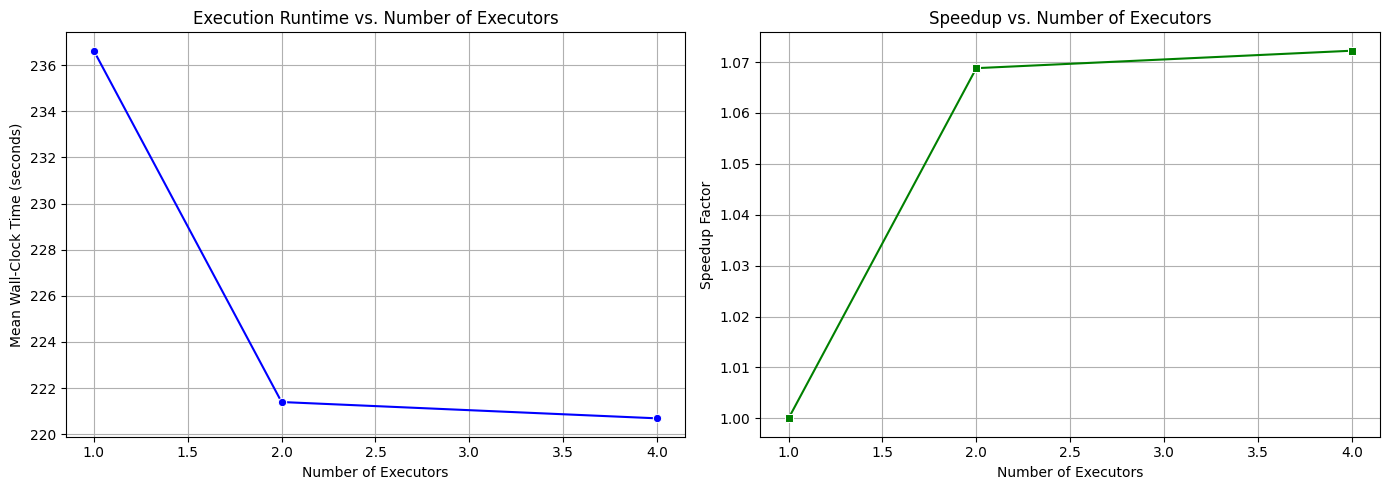

no org.apache.spark.deploy.worker.Worker to stop
stopping org.apache.spark.deploy.master.Master


In [17]:
# Spark for Big Data Preprocessing and Statistical Analysis (Airline Flight Delays)

import time
import os
import psutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from google.colab import drive

drive.mount("/content/drive")
dataset_path = "/content/drive/MyDrive/flights.csv"


# 1. Report Runtime Hardware Environment (CPU Cores & System RAM)
print("RUNTIME HARDWARE ENVIRONMENT REPORT")
cpu_count = os.cpu_count()
total_ram_gb = psutil.virtual_memory().total / (1024 ** 3)
print(f"Available CPU Cores (os.cpu_count()): {cpu_count}")
print(f"Total System RAM: {total_ram_gb:.2f} GB")

def create_spark_session(num_executors=1):
    """
    Creates a SparkSession connected directly to the Standalone Cluster.
    """
    spark = SparkSession.builder \
        .appName("FlightDelayStatisticalAnalysis-Standalone") \
        .master("spark://localhost:7077") \
        .config("spark.executor.instances", str(num_executors)) \
        .config("spark.executor.cores", "1") \
        .config("spark.driver.memory", "2g") \
        .config("spark.executor.memory", "2g") \
        .getOrCreate()
    return spark

executor_configs = [1, 2, 4]
num_repetitions = 3
benchmark_results = []


for num_exec in executor_configs:
    print(f"Running Configuration: {num_exec} Executor(s) [1 core each]")

    for rep in range(1, num_repetitions + 1):
        print(f"--- Repetition {rep} of {num_repetitions} ---")

        spark = create_spark_session(num_executors=num_exec)

        try:
            start_wall_time = time.time()

            # Load Dataset
            df = spark.read.csv(dataset_path, header=True, inferSchema=True)

            # Filter out cancelled flights, diverted flights, and October
            df = df.filter(
                (df["CANCELLED"] == 0) &
                (df["DIVERTED"] == 0) &
                (df["MONTH"] != 10)
            )

            # Check missing values and filter clean subset
            df = df.filter(
                df["ARRIVAL_DELAY"].isNotNull() &
                df["DEPARTURE_DELAY"].isNotNull() &
                df["DISTANCE"].isNotNull()
            )

            # Label flights arriving 15+ minutes late
            df = df.withColumn(
                "is_delayed_15",
                F.when(F.col("ARRIVAL_DELAY") >= 15, 1).otherwise(0)
            )

            # Report number of Spark partitions
            num_partitions = df.rdd.getNumPartitions()
            if rep == 1:
                print(f"[*] Number of Spark Partitions: {num_partitions}")

            # Cache dataframe for analytical queries
            df.cache()

            # Correlation and Statistical Analysis
            stats_df = df.select(
                F.mean("ARRIVAL_DELAY").alias("mean_arr_delay"),
                F.stddev("ARRIVAL_DELAY").alias("std_arr_delay"),
                F.mean("DEPARTURE_DELAY").alias("mean_dep_delay"),
                F.stddev("DEPARTURE_DELAY").alias("std_dep_delay"),
                F.mean("DISTANCE").alias("mean_distance"),
                F.stddev("DISTANCE").alias("std_distance")
            )
            stats_df.show()

            # Correlation analysis
            dep_arr_corr = df.stat.corr("DEPARTURE_DELAY", "ARRIVAL_DELAY")
            distance_arr_corr = df.stat.corr("DISTANCE", "ARRIVAL_DELAY")

            end_wall_time = time.time()
            total_wall_time = end_wall_time - start_wall_time
            print(f"Wall-clock time for {num_exec} executors (Rep {rep}): {total_wall_time:.2f} seconds")

            benchmark_results.append({
                "Executors": num_exec,
                "Repetition": rep,
                "WallClockTime_Sec": total_wall_time
            })

            df.unpersist()

        finally:
            spark.stop()

# Performance Summary (Mean ± SD) and Visualization
results_df = pd.DataFrame(benchmark_results)
summary_stats = results_df.groupby("Executors")["WallClockTime_Sec"].agg(["mean", "std"]).reset_index()

# Display of Mean ± SD
summary_stats["Mean_SD"] = summary_stats.apply(
    lambda row: f"{row['mean']:.2f} ± {row['std']:.2f} sec", axis=1
)

#
print("BENCHMARK SUMMARY STATISTICS (Mean ± SD)")
print(summary_stats[["Executors", "Mean_SD"]])

baseline_time = summary_stats.loc[summary_stats["Executors"] == 1, "mean"].values[0]
summary_stats["Speedup"] = baseline_time / summary_stats["mean"]

# Plotting Runtime and Speedup
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=summary_stats, x="Executors", y="mean", marker="o", ax=axes[0], color="b")
axes[0].set_title("Execution Runtime vs. Number of Executors")
axes[0].set_xlabel("Number of Executors")
axes[0].set_ylabel("Mean Wall-Clock Time (seconds)")
axes[0].grid(True)

sns.lineplot(data=summary_stats, x="Executors", y="Speedup", marker="s", ax=axes[1], color="g")
axes[1].set_title("Speedup vs. Number of Executors")
axes[1].set_xlabel("Number of Executors")
axes[1].set_ylabel("Speedup Factor")
axes[1].grid(True)

plt.tight_layout()
plt.savefig("statistical_analysis_scalability.png")
plt.show()

!/content/spark-3.5.0-bin-hadoop3/sbin/stop-worker.sh
!/content/spark-3.5.0-bin-hadoop3/sbin/stop-master.sh